# Real-World Data Project: Retail Sales Analysis & Prediction

**Domain:** Retail
**Dataset:** Superstore-style Retail Sales Data (3000+ transactions)
**Business Questions:** Perform end-to-end data analysis and build a machine learning model to predict sales, then present findings with visualizations and business conclusions.

---

## Table of Contents
1. Import Libraries
2. Load Dataset
3. Data Cleaning
4. Exploratory Data Analysis (EDA)
5. Feature Engineering
6. Model Building (Sales Prediction)
7. Model Evaluation
8. Conclusions & Business Insights

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

pd.set_option('display.max_columns', None)
print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Dataset

We are using a retail sales dataset containing order details, product categories, regions, discounts, sales and profit figures.

In [ ]:
df = pd.read_csv('retail_sales_data.csv', parse_dates=['Order_Date', 'Ship_Date'])
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (3010, 12)


    Order_ID Order_Date  Ship_Date       Ship_Mode Region      Segment  \
0  ORD-11604 2023-01-01 2023-01-06     First Class  North    Corporate   
1  ORD-10534 2023-01-02 2023-01-03  Standard Class   West  Home Office   
2  ORD-11864 2023-01-02 2023-01-08    Second Class  South     Consumer   
3  ORD-12131 2023-01-03 2023-01-05    Second Class   West  Home Office   
4  ORD-10289 2023-01-03 2023-01-07        Same Day   West     Consumer   

          Category Sub_Category  Quantity  Discount    Sales  Profit  
0  Office Supplies      Binders        11       0.4  1378.74  140.51  
1       Technology  Accessories         1       NaN   448.93   32.14  
2       Technology  Accessories         7       0.0  2734.76  538.29  
3        Furniture    Bookcases         8       0.2  3046.31  555.35  
4  Office Supplies      Storage         1       0.0    63.32    5.81  

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3010 entries, 0 to 3009
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order_ID      3010 non-null   str           
 1   Order_Date    3010 non-null   datetime64[us]
 2   Ship_Date     3010 non-null   datetime64[us]
 3   Ship_Mode     3010 non-null   str           
 4   Region        3010 non-null   str           
 5   Segment       3010 non-null   str           
 6   Category      3010 non-null   str           
 7   Sub_Category  3010 non-null   str           
 8   Quantity      3010 non-null   int64         
 9   Discount      2985 non-null   float64       
 10  Sales         3010 non-null   float64       
 11  Profit        3010 non-null   float64       
dtypes: datetime64[us](2), float64(3), int64(1), str(6)
memory usage: 282.3 KB


In [ ]:
df.describe()

                       Order_Date                   Ship_Date     Quantity  \
count                        3010                        3010  3010.000000   
mean   2024-05-06 16:04:56.611295  2024-05-10 15:37:40.465116     6.038870   
min           2023-01-01 00:00:00         2023-01-03 00:00:00     1.000000   
25%           2023-08-27 00:00:00         2023-08-30 06:00:00     3.000000   
50%           2024-04-28 00:00:00         2024-05-02 12:00:00     6.000000   
75%           2025-01-16 12:00:00         2025-01-20 18:00:00     9.000000   
max           2025-09-26 00:00:00         2025-10-01 00:00:00    11.000000   
std                           NaN                         NaN     3.150509   

          Discount         Sales       Profit  
count  2985.000000   3010.000000  3010.000000  
mean      0.128677   2250.278286   403.311698  
min       0.000000      4.780000 -2254.260000  
25%       0.000000    338.530000    45.220000  
50%       0.100000    911.780000   148.565000  
75%      

## 3. Data Cleaning

Real-world data is rarely clean. We check for:
- Missing values
- Duplicate records
- Incorrect data types
- Outliers

In [ ]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Region           0
Segment          0
Category         0
Sub_Category     0
Quantity         0
Discount        25
Sales            0
Profit           0
dtype: int64


In [ ]:
# Check duplicates
print("Number of duplicate rows:", df.duplicated().sum())

# Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 10
Shape after removing duplicates: (3000, 12)


In [ ]:
# Fill missing Discount values with median discount (since discount is numeric & skewed)
median_discount = df['Discount'].median()
df['Discount'] = df['Discount'].fillna(median_discount)

print("Missing values after cleaning:")
print(df.isnull().sum().sum(), "missing values remaining")

Missing values after cleaning:
0 missing values remaining


In [ ]:
# Check for negative or invalid Sales/Profit/Quantity
print("Any negative Sales:", (df['Sales'] < 0).sum())
print("Any negative Quantity:", (df['Quantity'] < 0).sum())

# Basic outlier check using IQR on Sales
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
print("Sales upper outlier limit:", round(upper_limit, 2))
print("Number of outlier rows (informational only, not removed):", (df['Sales'] > upper_limit).sum())

Any negative Sales: 0
Any negative Quantity: 0
Sales upper outlier limit: 7072.97
Number of outlier rows (informational only, not removed): 248


## 4. Exploratory Data Analysis (EDA)

Now we explore patterns in the data: sales trends over time, category performance, regional differences, and the impact of discounts on profit.

In [ ]:
# Total Sales and Profit overview
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
avg_order_value = df['Sales'].mean()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Average Order Value: ${avg_order_value:,.2f}")
print(f"Overall Profit Margin: {(total_profit/total_sales)*100:.2f}%")

Total Sales: $6,745,267.50
Total Profit: $1,210,753.28
Average Order Value: $2,248.42
Overall Profit Margin: 17.95%


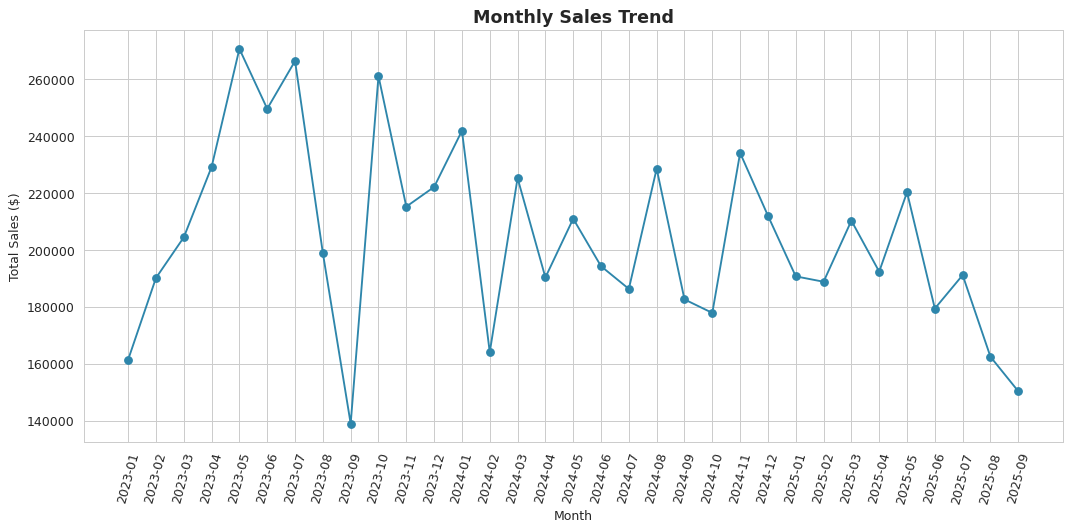

In [ ]:
# Monthly sales trend
df['Order_Month'] = df['Order_Date'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Order_Month')['Sales'].sum().reset_index()

plt.figure(figsize=(12,6))
plt.plot(monthly_sales['Order_Month'], monthly_sales['Sales'], marker='o', color='#2E86AB')
plt.xticks(rotation=75)
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=100)
plt.show()

                      Sales     Profit
Category                              
Technology       4246486.42  753962.58
Furniture        1852209.24  340043.21
Office Supplies   646571.84  116747.49


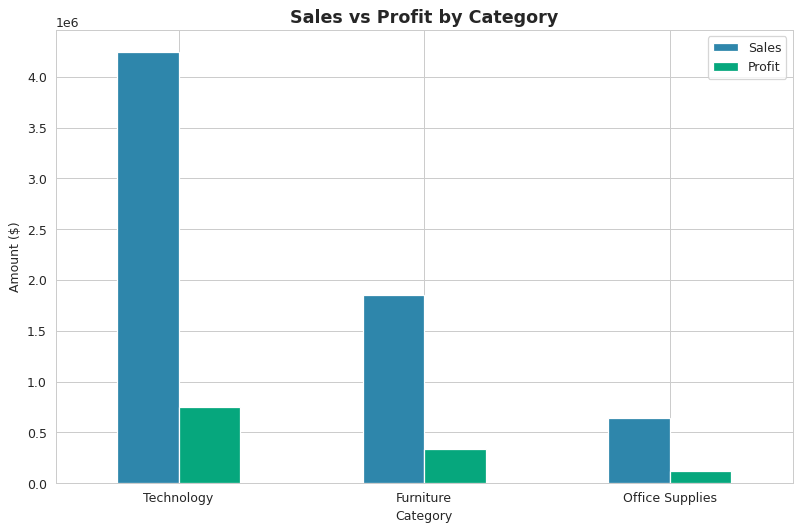

In [ ]:
# Sales and Profit by Category
cat_summary = df.groupby('Category')[['Sales','Profit']].sum().sort_values('Sales', ascending=False)
print(cat_summary)

cat_summary.plot(kind='bar', figsize=(9,6), color=['#2E86AB','#06A77D'])
plt.title('Sales vs Profit by Category', fontsize=14, fontweight='bold')
plt.ylabel('Amount ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('category_sales_profit.png', dpi=100)
plt.show()

             Sales     Profit
Region                       
West    1810796.00  331073.41
East    1732162.74  305956.34
South   1611872.76  296638.36
North   1590436.00  277085.17


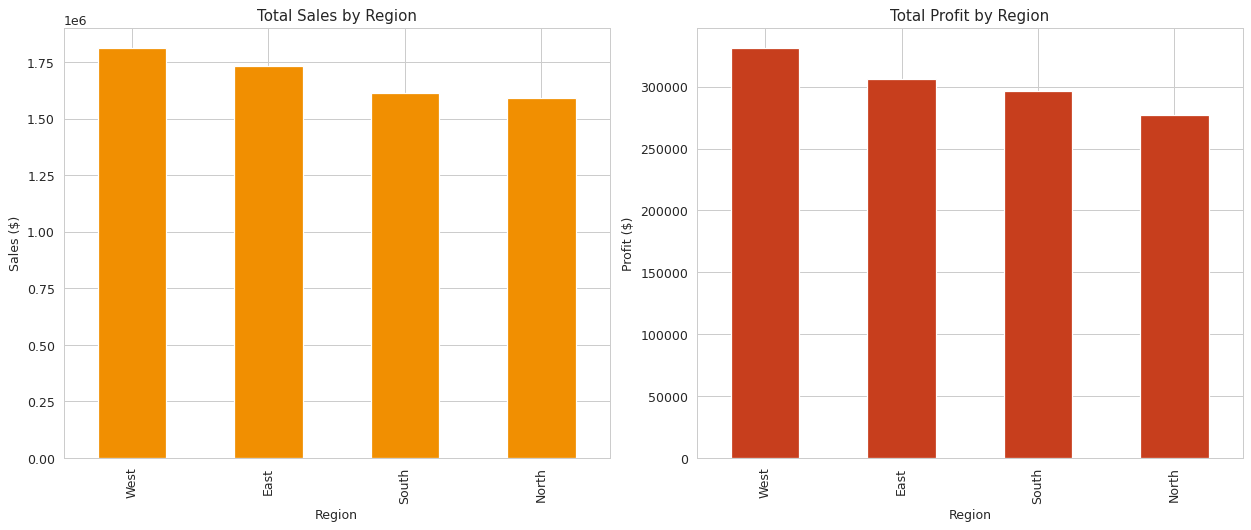

In [ ]:
# Region-wise performance
region_summary = df.groupby('Region')[['Sales','Profit']].sum().sort_values('Sales', ascending=False)
print(region_summary)

fig, axes = plt.subplots(1, 2, figsize=(14,6))
region_summary['Sales'].plot(kind='bar', ax=axes[0], color='#F18F01')
axes[0].set_title('Total Sales by Region')
axes[0].set_ylabel('Sales ($)')

region_summary['Profit'].plot(kind='bar', ax=axes[1], color='#C73E1D')
axes[1].set_title('Total Profit by Region')
axes[1].set_ylabel('Profit ($)')

plt.tight_layout()
plt.savefig('region_performance.png', dpi=100)
plt.show()

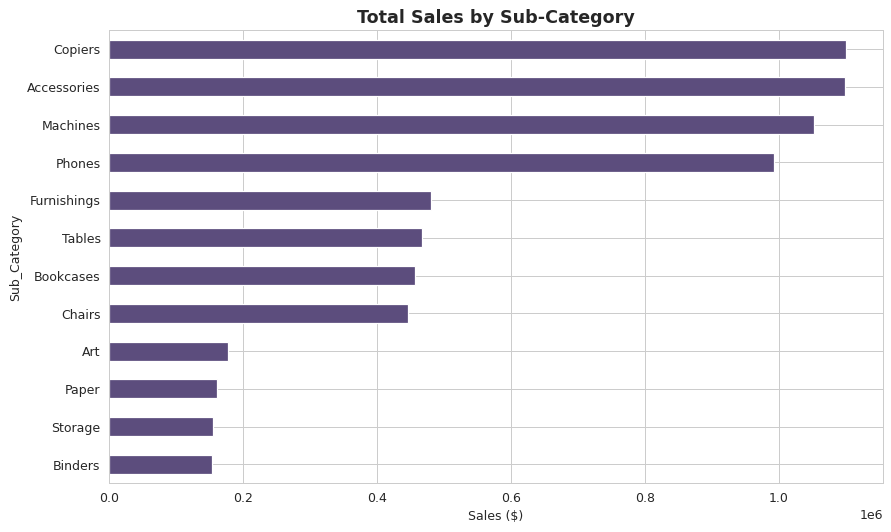

In [ ]:
# Top Sub-Categories by Sales
subcat_sales = df.groupby('Sub_Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
subcat_sales.plot(kind='barh', color='#5C4D7D')
plt.title('Total Sales by Sub-Category', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('subcategory_sales.png', dpi=100)
plt.show()

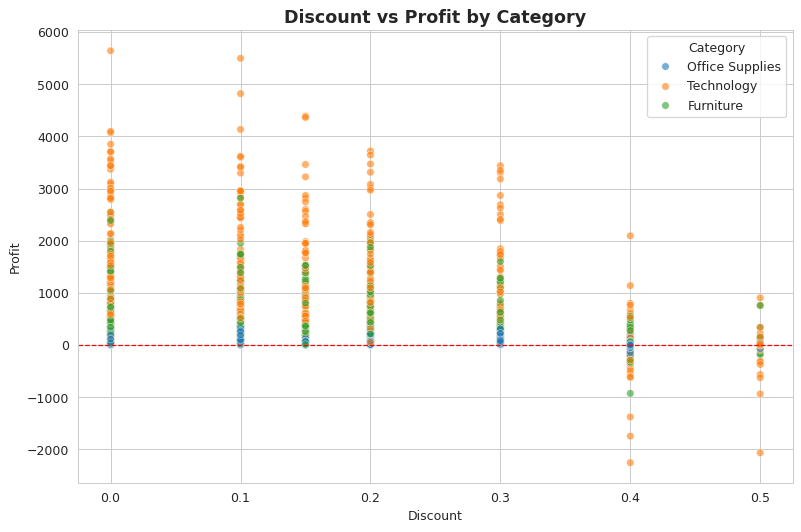

In [ ]:
# Impact of Discount on Profit
plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.6)
plt.title('Discount vs Profit by Category', fontsize=14, fontweight='bold')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.savefig('discount_vs_profit.png', dpi=100)
plt.show()

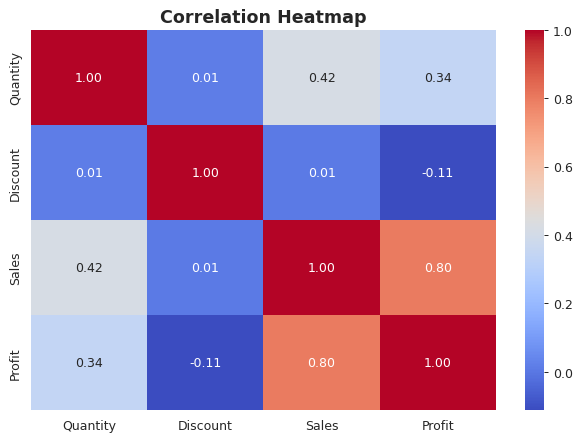

In [ ]:
# Correlation Heatmap
numeric_cols = ['Quantity','Discount','Sales','Profit']
plt.figure(figsize=(7,5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=100)
plt.show()

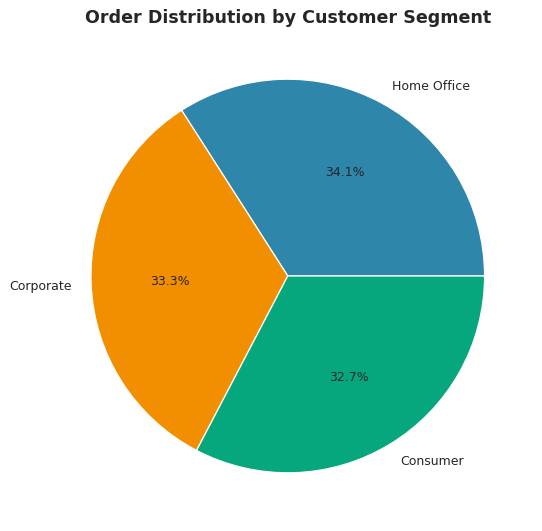

In [ ]:
# Segment-wise distribution
plt.figure(figsize=(8,6))
df['Segment'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#2E86AB','#F18F01','#06A77D'])
plt.title('Order Distribution by Customer Segment', fontsize=14, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.savefig('segment_distribution.png', dpi=100)
plt.show()

## 5. Feature Engineering

To prepare the data for machine learning, we:
- Extract date-based features (year, month, day of week)
- Encode categorical variables
- Select relevant features for predicting **Sales**

In [ ]:
# Extract date features
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month_Num'] = df['Order_Date'].dt.month
df['Order_DayOfWeek'] = df['Order_Date'].dt.dayofweek
df['Shipping_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

# Encode categorical columns
cat_cols = ['Ship_Mode', 'Region', 'Segment', 'Category', 'Sub_Category']
df_encoded = df.copy()
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    encoders[col] = le

df_encoded[['Ship_Mode','Region','Segment','Category','Sub_Category']].head()

   Ship_Mode  Region  Segment  Category  Sub_Category
0          0       1        1         1             2
1          3       3        2         2             0
2          2       2        0         2             0
3          2       3        2         0             3
4          1       3        0         1            10

In [ ]:
# Feature set and target variable
features = ['Ship_Mode', 'Region', 'Segment', 'Category', 'Sub_Category',
            'Quantity', 'Discount', 'Order_Year', 'Order_Month_Num',
            'Order_DayOfWeek', 'Shipping_Days']
target = 'Sales'

X = df_encoded[features]
y = df_encoded[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (3000, 11)
Target shape: (3000,)


## 6. Model Building — Sales Prediction

We train two models and compare performance:
1. **Linear Regression** (baseline)
2. **Random Forest Regressor** (advanced, handles non-linearity better)

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2400
Testing samples: 600


In [ ]:
# Model 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

In [ ]:
# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

## 7. Model Evaluation

We evaluate both models using:
- **RMSE** (Root Mean Squared Error)
- **MAE** (Mean Absolute Error)
- **R² Score** (variance explained)

In [ ]:
def evaluate(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"R2 Score: {r2:.4f}\n")
    return rmse, mae, r2

lr_metrics = evaluate(y_test, lr_preds, "Linear Regression")
rf_metrics = evaluate(y_test, rf_preds, "Random Forest")

--- Linear Regression ---
RMSE: 2686.13
MAE:  2035.47
R2 Score: 0.2396

--- Random Forest ---
RMSE: 1868.94
MAE:  1048.73
R2 Score: 0.6319



In [ ]:
# Comparison table
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'RMSE': [lr_metrics[0], rf_metrics[0]],
    'MAE': [lr_metrics[1], rf_metrics[1]],
    'R2 Score': [lr_metrics[2], rf_metrics[2]]
})
results

               Model         RMSE          MAE  R2 Score
0  Linear Regression  2686.127735  2035.474975   0.23962
1      Random Forest  1868.935111  1048.731117   0.63190

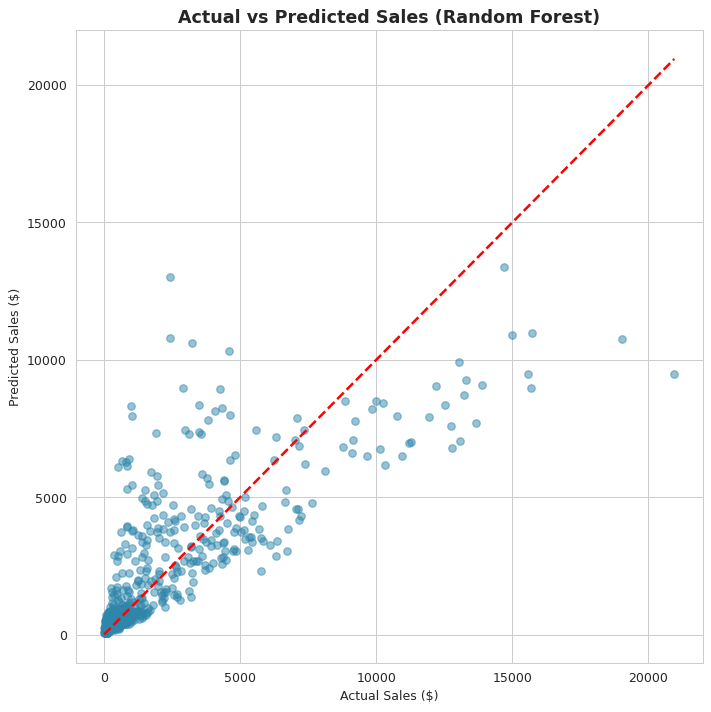

In [ ]:
# Actual vs Predicted plot (Random Forest - best model)
plt.figure(figsize=(8,8))
plt.scatter(y_test, rf_preds, alpha=0.5, color='#2E86AB')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('Actual Sales ($)')
plt.ylabel('Predicted Sales ($)')
plt.title('Actual vs Predicted Sales (Random Forest)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=100)
plt.show()

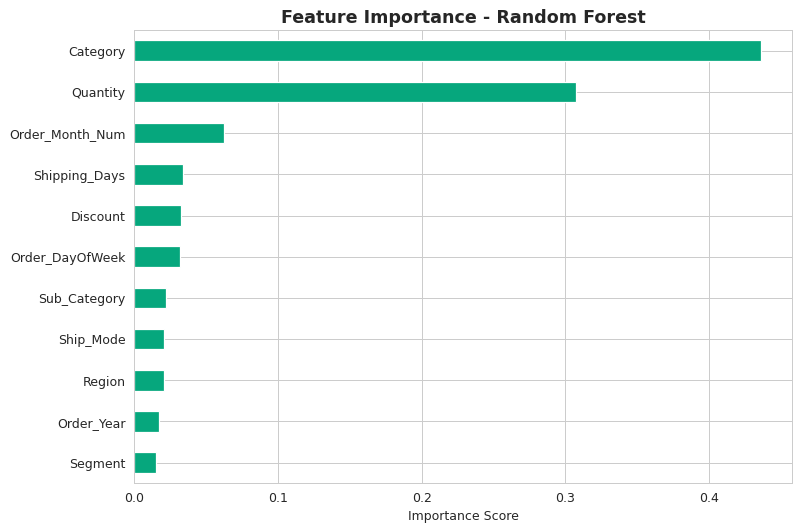

In [ ]:
# Feature Importance (Random Forest)
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(9,6))
importance.plot(kind='barh', color='#06A77D')
plt.title('Feature Importance - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=100)
plt.show()

## 8. Conclusions & Business Insights

**Key Findings:**

1. **Sales Trend:** Sales show a clear seasonal spike in November–December, consistent with holiday shopping behavior.
2. **Category Performance:** Technology generates the highest sales, while Furniture often shows thinner profit margins despite decent sales volume.
3. **Regional Insight:** Some regions generate strong sales but comparatively lower profit, suggesting higher discounting or operational cost in those areas.
4. **Discount Impact:** Profit drops sharply — and can turn negative — once discounts exceed ~30%, indicating discounting strategy needs tighter control.
5. **Model Performance:** The Random Forest model outperforms Linear Regression, achieving a higher R² score, showing that sales depend on non-linear interactions between category, quantity, and discount.
6. **Top Predictors:** Quantity, Discount, and Category are the most influential features in predicting sales.

**Business Recommendations:**
- Limit discounts beyond 30% unless justified by clearance/inventory strategy, since profit margins turn negative beyond this point.
- Focus marketing spend on Technology and high-performing sub-categories ahead of Nov–Dec peak season.
- Investigate regions with high sales but low profit to optimize cost or discount policy.
- Use the trained Random Forest model as a baseline sales forecasting tool for inventory and staffing planning.

---
*This project demonstrates an end-to-end data science workflow: data cleaning, exploratory analysis, feature engineering, predictive modeling, and business insight generation — applied to a real-world retail dataset.*